In [1]:
import os
import random
import operator
from tqdm import tqdm
import polars as pl
import seaborn as sns
from adjustText import adjust_text
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from functools import reduce
from pycytominer.feature_select import feature_select
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics.pairwise import cosine_distances
import networkx as nx
import community.community_louvain as community_louvain
import umap

import sys
sys.path.append("../../../../1_allele_collection/2_analysis")
from plot_utils import *
sys.path.append("../1_snakemake_pipeline/2025_varchamp_snakemake")
from img_utils import *
sys.path.append("../../..")
from analyses_plot_utils import *
from utils import *

sns.set_style(style='white')
sns.set_context("notebook", font_scale=.9)

# controls = {
#     "TC": ["EGFP"],
#     "NC": ["RHEB", "MAPK9", "PRKACB", "SLIRP"],
#     "PC": ["ALK", "ALK_Arg1275Gln", "PTK2B"],
#     # "cPC": ["KRAS", "PTK2B", "GHSR", "ABL1", "BRD4", 
#     # "OPRM1", "RB1", "ADA", "WT PMP22", "LYN", "TNF", 
#     # "CYP2A6", "CSK", "PAK1", "ALDH2", "CHRM3", "KCNQ2", 
#     # "ALK T1151M", "PRKCE", "LPAR1", "PLP1"]
# }
# ctrl_alleles = [k_v for k_v in controls.values()]
# ctrl_alleles_flat = [allele for sublist in ctrl_alleles for allele in sublist]
# # ctrl_alleles_flat

In [2]:
CLASS_RESULTS_DIR = "/home/shenrunx/igvf/varchamp/2025_varchamp_snakemake/2.snakemake_pipeline/outputs/classification_results"

imaging_summary_auroc_gfp = pl.read_csv(
    "/home/shenrunx/igvf/varchamp/2025_varchamp_snakemake/3.downstream_analyses/outputs/2.classification_results/imaging_analyses_classification_summary_all_gfp_adj_auroc.csv"
)

imaging_summary_clinvar = pl.read_csv("../../3_outputs/imaging_analyses_summary_clinvar.tsv", separator="\t", infer_schema_length=100000)
imaging_summary_clinvar = imaging_summary_clinvar.join(
    imaging_summary_auroc_gfp,
    left_on="gene_allele",
    right_on="allele_0",
    how="left"
)
allele_list = list(imaging_summary_clinvar["gene_allele"]) + list(imaging_summary_clinvar["Gene"].unique())

In [3]:
## classification results in SM pipeline
SM_CLASS_RES_DIR = CLASS_RESULTS_DIR + "/{batch_id}/profiles_tcdropped_filtered_var_mad_outlier_featselect_filtcells"
FEAT = "GFP"
MISLOCALIZED_LABEL = "Altered_95th_perc_both_batches_GFP"

## QC-ed PQ files
ALL_PROF_QC = PROF_DIR + "/{batch_id}/profiles_tcdropped_filtered_var_mad_outlier.parquet"
PASS_QC_PROF_PQ = PROF_DIR + "/{batch_id}/profiles_tcdropped_filtered_var_mad_outlier_featselect_filtcells.parquet"

np.random.seed(42)
random.seed(42)

In [99]:
feat_import_df_feat = pl.DataFrame()
for bio_rep, bio_rep_batches in BIO_REP_BATCHES_DICT.items():
    # print(bio_rep)
    for batch_id in bio_rep_batches:
        if bio_rep != "2024_12_Batch_11-12":
            batch_id_tmp = batch_id + "_morph"
        else:
            batch_id_tmp = batch_id

        bio_rep_batches = BIO_REP_BATCHES_DICT[bio_rep]
        ## ONLY grep the allele come from the bio-rep
        allele_batch_df = imaging_summary_clinvar.filter(pl.col("Metadata_Bio_Batch")==bio_rep)
        batch_allele_list = list(allele_batch_df["gene_allele"]) + list(allele_batch_df["Gene"].unique())
        # Read the data
        feat_df = pl.scan_csv(f"{SM_CLASS_RES_DIR.format(batch_id=batch_id_tmp)}/feat_importance_gfp_adj.csv")
        meta_cols = [c for c in feat_df.collect_schema().names() if c.startswith("Metadata_") or c.startswith("Group") or c == "Batch"]
        feat_cols = [c for c in feat_df.collect_schema().names() if c not in meta_cols and FEAT in c]
        feat_df_batch = feat_df.with_columns(
            [pl.col(c).cast(pl.Float64, strict=False).alias(c) for c in feat_cols]
        ).with_columns(
            pl.lit(batch_id).alias("Metadata_Batch"),
            pl.col("Group2").str.split('_').list.slice(-2).list.join("_").alias("Metadata_gene_allele")
        ).filter(
            (pl.col("Metadata_Feature_Type")==FEAT)&(~pl.col("Metadata_Control"))
            &(pl.col("Group1").is_in(allele_list)|(pl.col("Metadata_gene_allele").is_in(batch_allele_list)))
        ).select(meta_cols + feat_cols + ["Metadata_Batch", "Metadata_gene_allele"]).collect()
        feat_import_df_feat = pl.concat([feat_import_df_feat, feat_df_batch], how="diagonal")

In [100]:
key_alleles_df = imaging_summary_clinvar.drop_nulls("AUROC_Mean_GFP_Adj").to_pandas()
feat_df = pl.DataFrame()
importance_thres = 1e-3
top_num = 5

for j, allele in tqdm(key_alleles_df.iterrows()):
    batch_list = list(feat_import_df_feat.filter(
        pl.col("Metadata_gene_allele")==allele["gene_allele"]
    ).unique("Metadata_Batch")["Metadata_Batch"])
    allele_df = pl.DataFrame()
    # display(allele)
    if batch_list == []:
        continue

    for i, batch in enumerate(batch_list):
        batch_df = feat_import_df_feat.filter(
            (pl.col("Metadata_Batch")==batch)&(pl.col("Metadata_gene_allele")==allele["gene_allele"])
        )
        feat_cols = [col for col in batch_df.columns if "Metadata" not in col and "Group" not in col]
        batch_df = batch_df.filter(
            ~pl.all_horizontal(pl.col(feat_cols).is_null())
        )
        non_null_gfp = [col for col in feat_cols if not batch_df[col].is_null().any()]
        batch_df_col = (
            batch_df.select(non_null_gfp).mean()
           .transpose(include_header=True)
           .filter(pl.col("column_0") > importance_thres)
           .sort("column_0", descending=True)
        #    .head(top_num)["column"]
        #    .to_list()
        )
        if not allele_df.is_empty():
            allele_df = allele_df.join(
                batch_df_col.with_columns(
                    pl.col("column_0").alias(batch),
                    pl.col("column").alias("index"),
                ).select("index", batch),
                on="index",
                how="full",
                coalesce=True
            )
        else:
            allele_df = batch_df_col.with_columns(
                pl.col("column_0").alias(batch),
                pl.col("column").alias("index"),
            ).select("index", batch)
            
    allele_df = allele_df.with_columns(
        pl.mean_horizontal(pl.col([col for col in allele_df.columns if "Batch" in col])).alias("feat_importance"),
        pl.col("index").alias("cp_feature")
    ).select(
        pl.col(["cp_feature", "feat_importance"])
    ).rename(
        {"feat_importance": allele["gene_allele"]}
    )
    if not feat_df.is_empty():
        feat_df = feat_df.join(
            allele_df,
            left_on="cp_feature",
            right_on="cp_feature",
            how="full",
            coalesce=True
        )
    else:
        feat_df = allele_df

816it [02:11,  6.21it/s]


In [ ]:
# feat_df.write_csv("../../3_outputs/feat_importance_gfp_filtered_all_alleles.csv")

In [7]:
feat_df = pl.read_csv("../../3_outputs/feat_importance_gfp_filtered_all_alleles.csv")
feat_df

cp_feature,KCTD1_Gly62Asp,CFP_Tyr414Asp,TH_Arg89Arg,AGXT_Gly161Ser,IL36RN_Lys35Arg,KRT6A_Asn171Ser,KCTD1_Ala30Glu,NCF2_Asp108Val,THAP1_Val193Ile,DCX_Arg59His,SH3BP2_Pro418His,AGXT_Pro11Leu,SMAD3_Asp408His,AGXT_Gly116Arg,HPRT1_Asp194Glu,AGXT_Pro11His,AGXT_Ala248Ser,TPM1_Lys37Glu,DES_Arg227Cys,SFTPC_Leu194Pro,KCTD1_His33Pro,POLR1C_Arg279Trp,STAR_Val187Met,GALE_Leu313Met,SMAD3_Arg287Trp,KRT8_Gly55Ala,KRT4_Glu449Lys,GLYCTK_His490Tyr,AP2S1_Arg15Cys,DES_Val56Leu,AGXT_Pro10Ala,AGXT_Ile340Met,AGXT_Asp129His,SMAD3_Cys109Tyr,CDKN1A_Ser31Arg,DCX_Arg196Cys,…,ZC4H2_Lys217Arg,BRCA1_Thr37Lys,RET_Arg313Gln,F9_Cys335Trp,LMNA_Arg386Thr,BRCA1_Thr581Ile,RAF1_Thr145Pro,SHOC2_Leu174Phe,SDHD_His102Arg,BRCA1_Cys64Ser,SHOC2_Gln269Arg,FARS2_Ala166Thr,RAD51D_Gly289Ser,BRCA1_Arg391Met,BRCA1_Lys502Glu,GSS_Arg125Cys,BRCA1_His299Tyr,BRCA1_Met1Ile,RAD51D_Asn138His,RAF1_Leu603Pro,SDHD_Gly138Val,RAF1_Leu613Val,CTCF_Arg342Cys,FH_Gln376Pro,LMNA_Arg377Leu,FH_Asn340Lys,FH_Ser334Arg,CTCF_Tyr407Cys,KRAS_Gly12Asp,F9_Asp110Asn,BRAF_Leu245Phe,F9_Arg226Gln,F9_Tyr161Cys,ABCD1_Arg389Gly,RAD51D_Glu233Gly,BRCA1_Arg71Lys,LMNA_Ala43Thr
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""Cells_Correlation_K_GFP_AGP""",null,0.009475,null,null,0.011265,null,null,null,null,null,null,null,0.010664,null,null,null,null,0.01475,null,null,null,null,null,null,0.007484,null,null,null,0.018448,null,null,null,null,0.005252,0.007244,null,…,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,0.011873,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null
"""Cells_Correlation_RWC_GFP_AGP""",null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,…,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,0.008004,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null
"""Nuclei_RadialDistribution_Frac…",0.006004,null,0.005995,0.010744,null,0.004952,0.007013,0.01302,0.013598,0.013904,0.011181,0.009006,null,0.051614,0.008052,0.007029,0.006545,null,0.006996,0.00426,0.014116,0.005572,0.006552,0.011106,null,null,0.012118,0.012449,null,0.004491,0.010589,0.006823,0.00971,null,null,0.014707,…,0.007099,0.002081,0.003653,0.003493,0.006479,0.00525,null,0.003227,0.006575,0.005952,0.005971,0.004956,0.006196,0.002809,0.005011,0.006458,0.001141,0.005895,0.001576,0.018311,0.005632,null,0.004433,null,0.001237,0.005306,0.002264,0.004208,0.003885,0.007819,0.012375,0.006762,0.003407,0.004681,0.004665,0.002082,0.004198
"""Cells_Intensity_MaxIntensityEd…",null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,…,0.005495,0.007102,0.005094,0.008259,0.004419,0.006011,0.006594,0.010892,0.006072,0.00668,0.008993,0.003875,0.046647,0.00584,0.010848,0.007729,0.004617,0.01446,0.052676,0.013756,0.006648,0.004339,0.005498,0.001005,0.00556,0.008559,0.005567,0.006203,0.00695,0.005229,0.006677,0.005571,0.009122,0.005463,0.008387,0.007721,0.007396
"""Nuclei_Correlation_RWC_DNA_GFP""",0.008122,0.005915,0.005841,0.006388,0.0077,0.006009,0.007929,0.014743,0.004921,0.006588,0.017373,0.006641,0.00685,0.005923,0.004478,0.006283,0.007656,0.005762,0.005401,0.043505,0.009715,0.009104,0.006145,0.005031,0.013471,0.003483,0.004152,0.010533,0.006462,0.004834,0.007315,0.006485,0.00676,0.005245,0.004673,0.006854,…,0.004313,0.004202,0.006615,0.006587,0.009612,0.007337,0.00719,0.007807,0.005218,0.005421,0.006161,0.005293,0.005743,0.001863,0.005656,0.006663,0.005381,0.004158,0.006205,0.007923,0.006923,0.003551,0.005122,0

In [8]:
allele_meta_df = pl.DataFrame()
allele_meta_df_dict, img_well_qc_sum_dict = {}, {}
for bio_rep, bio_rep_batches in BIO_REP_BATCHES_DICT.items():
    for batch_id in bio_rep_batches:
        allele_meta_df_batch = pl.DataFrame()
        platemaps = [file for file in os.listdir(PLATEMAP_DIR.format(batch_id=batch_id)) if file.endswith(".txt")]
        for platemap in platemaps:
            platemap_df = pl.read_csv(os.path.join(PLATEMAP_DIR.format(batch_id=batch_id), platemap), separator="\t", infer_schema_length=100000)
            allele_meta_df_batch = pl.concat([allele_meta_df_batch, 
                                        platemap_df.filter((pl.col("node_type").is_not_null()))], # (~pl.col("node_type").is_in(["TC","NC","PC"]))&
                                        how="diagonal_relaxed").sort("plate_map_name")
            allele_meta_df_batch = allele_meta_df_batch.with_columns(pl.col("plate_map_name").alias("plate_map")) ## str.split('_').list.get(0).
            # display(allele_meta_df.head())
        allele_meta_df = pl.concat([
            allele_meta_df,
            allele_meta_df_batch
        ], how="diagonal_relaxed")#.sort("plate_map_name") ## (~pl.col("node_type").is_in(["TC","NC","PC"]))&
    allele_meta_df_dict[bio_rep] = allele_meta_df_batch

    img_well_qc_sum = pl.read_csv(f"{IMGS_QC_METRICS_DIR}/{bio_rep}/plate-well-level_img_qc_sum.csv")
    img_well_qc_sum = img_well_qc_sum.with_columns(
        pl.col("channel").replace("DAPI", "DNA").alias("channel")
    )
    img_well_qc_sum_morph = img_well_qc_sum.filter(pl.col("channel")!="GFP")
    img_well_qc_sum_morph = img_well_qc_sum_morph.group_by(["plate","well"]).agg(
        pl.col("is_bg").max().alias("is_bg"),
        pl.col("s2n_ratio").mean().alias("s2n_ratio")
    ).with_columns(pl.lit("Morph").alias("channel"))
    img_well_qc_sum = pl.concat([
        img_well_qc_sum.select(pl.col(["plate","well","channel","is_bg","s2n_ratio"])),
        img_well_qc_sum_morph.select(pl.col(["plate","well","channel","is_bg","s2n_ratio"])),
    ], how="vertical_relaxed")
    img_well_qc_sum_dict[bio_rep] = img_well_qc_sum

In [9]:
imaging_summary_clinvar.drop_nulls("AUROC_Mean_GFP_Adj").filter(
    pl.col("AUROC_Mean_GFP_Adj")>=0.9577
)

Gene,gene_allele,U2OS_cc_t_stat,U2OS_cc_t_pval,U2OS_prot_abun_t_stat,U2OS_prot_abun_t_pval,Metadata_Bio_Batch,Altered_95th_perc_both_batches_GFP,Altered_95th_perc_both_batches_DNA,Altered_95th_perc_both_batches_Mito,Altered_95th_perc_both_batches_AGP,Altered_95th_perc_both_batches_Morph,Altered_99th_perc_both_batches_GFP,Altered_99th_perc_both_batches_DNA,Altered_99th_perc_both_batches_Mito,Altered_99th_perc_both_batches_AGP,Altered_99th_perc_both_batches_Morph,AUROC_Mean_GFP,AUROC_Mean_DNA,AUROC_Mean_Mito,AUROC_Mean_AGP,AUROC_Mean_Morph,AUROC_BioRep1_Morph,AUROC_BioRep1_AGP,AUROC_BioRep1_Mito,AUROC_BioRep1_DNA,AUROC_BioRep1_GFP,AUROC_BioRep2_Morph,AUROC_BioRep2_AGP,AUROC_BioRep2_Mito,AUROC_BioRep2_DNA,AUROC_BioRep2_GFP,Gene_right,U2OS_cc_t_stat_right,U2OS_cc_t_pval_right,U2OS_prot_abun_t_stat_right,U2OS_prot_abun_t_pval_right,…,protein_00001200-b-1 avg,protein_00001200-b-1 outliers⁺⁺,protein_00001200-c-1 avg,protein_00001200-c-1 outliers⁺⁺,protein_00001200-d-1 avg,protein_00001200-d-1 outliers⁺⁺,protein_00001200-e-1 avg,protein_00001200-e-1 outliers⁺⁺,protein_00000061-a-1 avg,protein_00000061-a-1 outliers⁺⁺,protein_00000061-b-1 avg,protein_00000061-b-1 outliers⁺⁺,protein_00000061-c-1 avg,protein_00000061-c-1 outliers⁺⁺,protein_00000061-d-1 avg,protein_00000061-d-1 outliers⁺⁺,protein_00000061-e-1 avg,protein_00000061-e-1 outliers⁺⁺,protein_00000061-f-1 avg,protein_00000061-f-1 outliers⁺⁺,protein_00000061-g-1 avg,protein_00000061-g-1 outliers⁺⁺,protein_00000061-h-1 avg,protein_00000061-h-1 outliers⁺⁺,protein_00000061-i-1 avg,protein_00000061-i-1 outliers⁺⁺,protein_00001002-a-1 avg,protein_00001002-a-1 outliers⁺⁺,protein_00000001-d-2 avg,protein_00000001-d-2 outliers⁺⁺,protein_00001050-a-1 avg,protein_00001050-a-1 outliers⁺⁺,protein_00000703-a-1 avg,protein_00000703-a-1 outliers⁺⁺,protein_00001087-a-1 avg,protein_00001087-a-1 outliers⁺⁺,AUROC_Mean_GFP_Adj
str,str,f64,f64,f64,f64,str,bool,bool,bool,bool,bool,bool,bool,bool,bool,bool,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,f64,f64,f64,f64,…,f64,str,f64,str,f64,str,f64,str,f64,str,f64,str,f64,str,f64,str,f64,str,f64,str,f64,str,f64,str,f64,str,f64,str,f64,str,str,str,str,str,str,str,f64
"""KRT8""","""KRT8_Gly55Ala""",-5.947322,0.009506,-4.275968,0.007894,"""2024_01_Batch_7-8""",true,true,true,false,false,true,true,false,false,false,0.995248,0.983045,0.991975,0.976227,0.951323,0.951323,0.976227,0.991975,0.983045,0.995248,null,null,null,null,null,"""KRT8""",-5.947322,0.009506,-4.275968,0.007894,…,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,0.990387
"""SMAD3""","""SMAD3_Cys109Tyr""",-7.258605,0.000169,-9.073729,0.00004,"""2025_03_Batch_15-16""",true,true,true,true,false,true,true,true,true,false,0.994906,0.960946,0.989817,0.974096,0.587013,0.545764,0.967812,0.994578,0.952952,0.995539,0.628262,0.98038,0.985055,0.968939,0.994272,"""SMAD3""",-7.258605,0.000169,-9.073729,0.00004,…,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,0.98084
"""LITAF""","""LITAF_Leu122Val""",3.517123,0.013803,-6.830851,0.000254,"""2025_03_Batch_15-16""",true,true,false,true,false,false,false,false,false,false,0.975048,0.870569,0.8827,0.930593,0.767215,0.701831,0.919758,0.881283,0.815427,0.965209,0.832599,0.941429,0.884117,0.925711,0.984887,"""LITAF""",3.517123,0.013803,-6.830851,0.000254,…,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,0.960413
"""NT5C3A""","""NT5C3A_Gly202Arg""",-0.924529,0.385973,-9.144145,0.000038,"""2025_03_Batch_15-16""",true,false,true,true,false,false,false,false,false,false,0.988908,0.645807,0.951298,0.931699,0.539863,0.562866,0.920814,0.948334,0.667593,0.983695,0.51685

In [10]:
allele_hits = imaging_summary_clinvar.drop_nulls("AUROC_Mean_GFP_Adj").filter(
    pl.col("AUROC_Mean_GFP_Adj")>=0.9577
)["gene_allele"].to_list()

In [11]:
ref_var_profiles = pl.DataFrame()
for bio_rep, bio_rep_batches in BIO_REP_BATCHES_DICT.items():
    # print(bio_rep)
    for batch_id in bio_rep_batches:
        if bio_rep != "2024_12_Batch_11-12":
            batch_id_tmp = batch_id + "_morph"
        else:
            batch_id_tmp = batch_id

        bio_rep_batches = BIO_REP_BATCHES_DICT[bio_rep]
        ## ONLY grep the allele come from the bio-rep
        allele_batch_df = imaging_summary_clinvar.filter(pl.col("Metadata_Bio_Batch")==bio_rep)
        batch_allele_list = list(allele_batch_df["gene_allele"]) + list(allele_batch_df["Gene"].unique())
        # Read the data
        gfp_adj_filtered_profiles = pl.scan_parquet(f"{SM_CLASS_RES_DIR.format(batch_id=batch_id_tmp)}/gfp_adj_filtered_cells_profiles.parquet").collect()
        ref_var_profiles = pl.concat([ref_var_profiles, gfp_adj_filtered_profiles], how="diagonal_relaxed")

In [12]:
# ref_var_profiles #.filter(pl.col("Metadata_refvar_gfp_adj_classify").str.contains("SMAD3_Cys109Tyr"))["Nuclei_RadialDistribution_MeanFrac_GFP_10of10"]

In [27]:
norm_vars_feat_df, norm_var_sc_feat_df = pl.DataFrame(), pl.DataFrame()

for allele in allele_hits:
    # print(allele)
    allele_profiles = ref_var_profiles.filter(pl.col("Metadata_refvar_gfp_adj_classify").str.contains(allele))
    # display(allele_profiles.head(2))
    sig_diff_feat = [c for c in feat_df["cp_feature"] if c in allele_profiles.columns]
    # display(allele_profiles.filter(pl.col("Metadata_control_type")!="allele").select(sig_diff_feat).head(2))
    gene_mean = allele_profiles.filter(pl.col("Metadata_symbol")==pl.col("Metadata_gene_allele")).select(sig_diff_feat).mean().to_numpy()[0].tolist()
    gene_std = allele_profiles.filter(pl.col("Metadata_symbol")==pl.col("Metadata_gene_allele")).select(sig_diff_feat).std().to_numpy()[0].tolist()
    # print(gene_mean, gene_std)

    z_norm_var_sc_feat_df = allele_profiles.filter(
        pl.col("Metadata_symbol")!=pl.col("Metadata_gene_allele")
    ).with_columns(
        [((pl.col(col) - pl.lit(gene_mean[i])) / pl.lit(gene_std[i])).alias(col)
        for i, col in enumerate(sig_diff_feat)]
    )
    norm_var_sc_feat_df = pl.concat([
        norm_var_sc_feat_df,
        z_norm_var_sc_feat_df
    ])
    z_norm_var_feat_df = z_norm_var_sc_feat_df.group_by(
        "Metadata_gene_allele", "Metadata_Plate", "Metadata_Well" ## aggregate by well first
    ).agg(
        pl.col(col).mean().alias(col)
        for col in sig_diff_feat
    ).group_by(
        "Metadata_gene_allele" ## aggregate by allele
    ).agg(
        pl.col(col).median().alias(col)
        for col in sig_diff_feat
    )#.to_pandas().set_index("Metadata_gene_allele")[sig_diff_feat]
    # display(z_norm_var_feat_df.head(2))

    norm_vars_feat_df = pl.concat([norm_vars_feat_df, 
                                   z_norm_var_feat_df], 
                                  how="diagonal")

In [29]:
norm_var_sc_feat_df

Metadata_plate_map_name,Metadata_well_position,Metadata_control_type,Metadata_symbol,Metadata_gene_allele,Metadata_imaging_well,Metadata_imaging_plate_R1,Metadata_imaging_plate_R2,Metadata_orf_id_wt,Metadata_ccsb_mutation_id,Metadata_nt_change_cdna,Metadata_aa_change,Metadata_allele_set,Metadata_imaging_plate,Metadata_batch1,Metadata_batch2,Metadata_clone_ID,Metadata_hgmd_ID,Metadata_clinvar_allele_ID,Metadata_clinvar_clinical_significance,Metadata_vector,Metadata_notes,Metadata_plate,Metadata_quad,Metadata_c96,Metadata_r96,Metadata_r384,Metadata_c384,Metadata_r384_letter,Metadata_Well,Metadata_TableNumber,Metadata_ImageNumber,Metadata_Cytoplasm_Parent_Cells,Metadata_Cytoplasm_Parent_Nuclei,Metadata_ImageNumber_1,Metadata_ImageNumber_2,Metadata_ImageNumber_3,…,Cells_Granularity_6_GFP,Nuclei_Texture_InfoMeas1_GFP_10_01_256,Cytoplasm_Texture_AngularSecondMoment_GFP_20_00_256,Nuclei_Texture_InfoMeas2_GFP_20_03_256,Nuclei_Texture_Entropy_GFP_20_03_256,Nuclei_Texture_InfoMeas1_GFP_5_03_256,Cells_Texture_InfoMeas1_GFP_20_00_256,Nuclei_Texture_InfoMeas1_GFP_5_01_256,Cytoplasm_Texture_InfoMeas1_GFP_10_03_256,Nuclei_Texture_InfoMeas2_GFP_5_02_256,Cells_Texture_InfoMeas1_GFP_20_02_256,Cells_Intensity_MinIntensity_GFP,Nuclei_Texture_SumAverage_GFP_5_01_256,Cytoplasm_Texture_Entropy_GFP_10_01_256,Cytoplasm_Location_CenterMassIntensity_Y_GFP,Nuclei_RadialDistribution_RadialCV_GFP_7of10,Cytoplasm_Texture_InfoMeas2_GFP_20_00_256,Nuclei_Texture_DifferenceVariance_GFP_20_01_256,Nuclei_Texture_SumAverage_GFP_5_03_256,Cytoplasm_Texture_AngularSecondMoment_GFP_20_01_256,Nuclei_Texture_SumAverage_GFP_5_02_256,Cytoplasm_Correlation_RWC_Mito_GFP,Cells_Texture_InverseDifferenceMoment_GFP_10_00_256,Nuclei_Intensity_MaxIntensity_GFP,Cells_Intensity_LowerQuartileIntensity_GFP,Cytoplasm_Texture_SumAverage_GFP_20_03_256,Cells_Texture_InfoMeas2_GFP_5_00_256,Cytoplasm_Correlation_RWC_GFP_Mito,Cytoplasm_Texture_AngularSecondMoment_GFP_10_01_256,Nuclei_Intensity_MinIntensity_GFP,Cytoplasm_Texture_InverseDifferenceMoment_GFP_5_02_256,Cytoplasm_Texture_AngularSecondMoment_GFP_5_02_256,Nuclei_Texture_SumAverage_GFP_10_00_256,Cells_Texture_InverseDifferenceMoment_GFP_10_02_256,Cytoplasm_Texture_SumAverage_GFP_10_01_256,Cells_Texture_DifferenceVariance_GFP_10_01_256,Cytoplasm_Texture_InverseDifferenceMoment_GFP_10_00_256
str,str,str,str,str,str,str,str,f64,str,str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,i64,i64,i64,i64,i64,i64,str,str,i64,i64,i64,i64,i64,i64,i64,…,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32
"""B7A1R1_P2""","""F10""","""allele""","""KRT8""","""KRT8_Gly55Ala""","""F10""","""B7A1R1_P2""","""B8A1R2_P2""",14966.0,"""218513.0""","""158G>T""","""Gly53Val""",1.0,2.0,7.0,8.0,null,null,null,null,527.0,null,2,4,5,3,6,10,"""F""","""F10""",3786147928,1163,2,2,1163,1163,1163,…,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null
"""B7A1R1_P2""","""F10""","""allele""","""KRT8""","""KRT8_Gly55Ala""","""F10""","""B7A1R1_P2""","""B8A1R2_P2""",14966.0,"""218513.0""","""158G>T""","""Gly53Val""",1.0,2.0,7.0,8.0,null,null,null,null,527.0,null,2,4,5,3,6,10,"""F""","""F10""",4255700538,1170,5,5,1170,1170,1170,…,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null
"""B7A1R1_P2""","""F10""","""allele""","""KRT8""","""KRT8_Gly55Ala""","""F10""","""B7A1R1_P2""","""B8A1R2_P2""",14966.0,"""218513.0""","""158G>T""","""Gly53Val""",1.0,2.0,7.0,8.0,null,null,null,null,527.0,null,2,4,5,3,6,10,"""F""","""F10""",887149496,1168,6,6,1168,1168,1168,…,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null

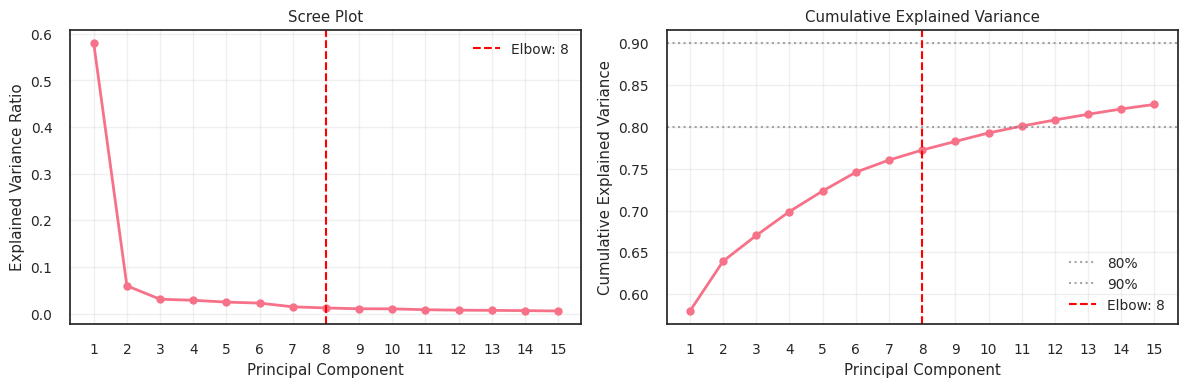

Optimal components: 8
Explained variance at elbow: 77.2%


In [30]:
# Fit PCA with all components
feature_cols = [c for c in norm_var_sc_feat_df.columns if "Metadata" not in c]

norm_vars_feat_meta_df = norm_var_sc_feat_df.with_columns(
    [pl.col(col).fill_null(0).alias(col) for col in feature_cols]
)

pca_full = PCA()
pca_full.fit(norm_vars_feat_meta_df.select(feature_cols).to_numpy())

# Calculate variances
explained_variance_ratio = pca_full.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance_ratio)

from kneed import KneeLocator
# Find elbow point using KneeLocator
knee_locator = KneeLocator(
    range(1, len(explained_variance_ratio)+1),
    explained_variance_ratio,
    curve='convex',
    direction='decreasing'
)
optimal_components = knee_locator.knee

# explained_var_thres = 0.6
# cumvar = np.cumsum(pca_full.explained_variance_ratio_)
# optimal_components = np.argmax(cumvar >= explained_var_thres) + 1

# Plot results
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

# Scree plot
n_show = min(15, len(explained_variance_ratio))
ax1.plot(range(1, n_show + 1), explained_variance_ratio[:n_show], 'o-', linewidth=2)
ax1.axvline(x=optimal_components, color='red', linestyle='--', label=f'Elbow: {optimal_components}')
ax1.set_xlabel('Principal Component')
ax1.set_ylabel('Explained Variance Ratio')
ax1.set_title('Scree Plot')
ax1.set_xticks(range(1, n_show + 1))
ax1.legend()
ax1.grid(True, alpha=0.3)

# Cumulative variance plot
ax2.plot(range(1, n_show + 1), cumulative_variance[:n_show], 'o-', linewidth=2)
ax2.axhline(y=0.8, color='gray', linestyle=':', alpha=0.7, label='80%')
ax2.axhline(y=0.9, color='gray', linestyle=':', alpha=0.7, label='90%')
ax2.axvline(x=optimal_components, color='red', linestyle='--', label=f'Elbow: {optimal_components}')
ax2.set_xlabel('Principal Component')
ax2.set_ylabel('Cumulative Explained Variance')
ax2.set_title('Cumulative Explained Variance')
ax2.set_xticks(range(1, n_show + 1))
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Results
print(f"Optimal components: {optimal_components}")
print(f"Explained variance at elbow: {cumulative_variance[optimal_components-1]:.1%}")

# Apply optimal PCA
pca = PCA(n_components=optimal_components)
data_pca = pca.fit_transform(norm_vars_feat_meta_df.select(feature_cols).to_numpy())

In [31]:
# UMAP plot
reducer = umap.UMAP(n_components=2, random_state=42, n_jobs=1) ## metric='cosine', 
umap_embedding = reducer.fit_transform(data_pca)

In [32]:
# Generate k-NN graph
k = 15  # adjust based on testing
nbrs = NearestNeighbors(n_neighbors=k, metric='cosine')
nbrs.fit(data_pca)
distances, indices = nbrs.kneighbors(data_pca)

# Build unweighted graph
G = nx.Graph()
for i in range(len(data_pca)):
    for j in indices[i][1:]:  # skip self
        G.add_edge(i, j)

# Louvain clustering
cluster_dict = community_louvain.best_partition(G) # , resolution=2

In [33]:
dr_res_df = pd.DataFrame(
    data_pca,
    columns=[f"PC{i}" for i in range(1, data_pca.shape[1]+1)]
)
dr_res_df = pd.concat([
    dr_res_df,
    pd.DataFrame(umap_embedding, 
                 columns=["UMAP1", "UMAP2"])
    ],
    axis=1
)
dr_res_df["cluster"] = dr_res_df.index.map(cluster_dict)
# dr_res_df["Metadata_AUROC_Mean_GFP"] = norm_vars_feat_meta_df["Metadata_AUROC_Mean_GFP"]
# dr_res_df["Metadata_Altered_95th_perc_both_batches_GFP"] = norm_vars_feat_meta_df["Metadata_Altered_95th_perc_both_batches_GFP"]
dr_res_df.index = norm_vars_feat_meta_df["Metadata_gene_allele"]

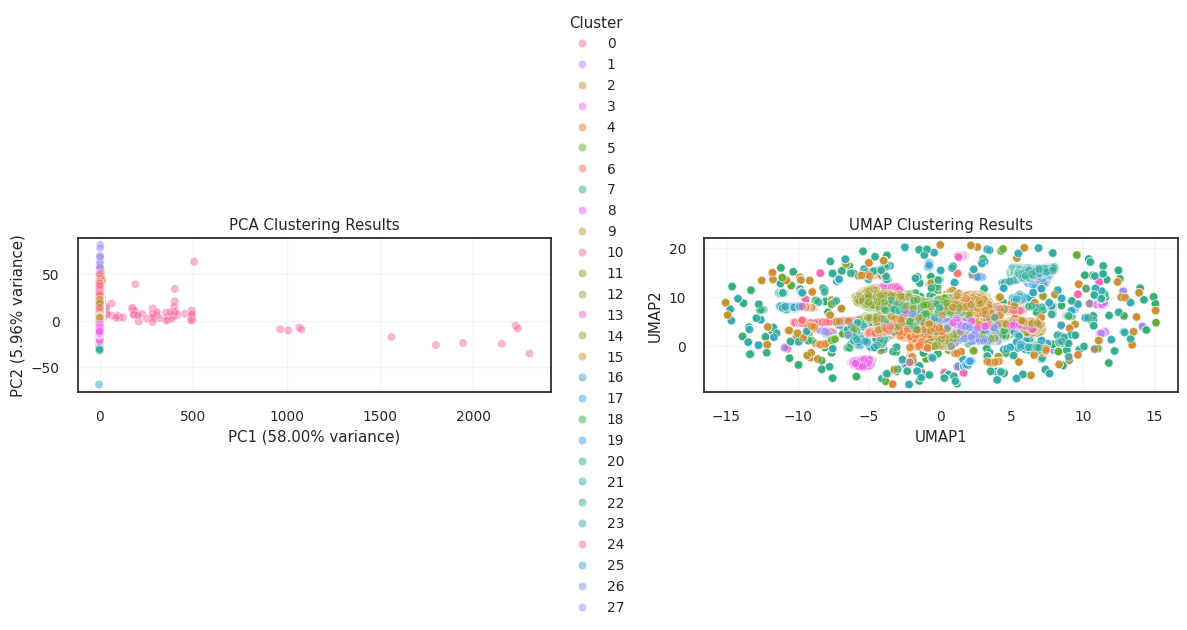

In [34]:
# Get unique clusters and create color palette
n_clusters = len(np.unique(dr_res_df["cluster"]))
colors = sns.color_palette("husl", n_clusters)
color_map = {cluster: colors[i] for i, cluster in enumerate(dr_res_df["cluster"].unique())}
auroc_thres = 0.95

fig, ax = plt.subplots(1,2, figsize=(12, 4.5))
# PCA plot
sns.scatterplot(
    dr_res_df,
    x="PC1",
    y="PC2",
    hue="cluster",
    palette=color_map,
    ax=ax[0],
    alpha=.5,
    # legend=False
)
# for cluster in unique_clusters:
#     mask = np.array(clusters) == cluster
#     ax[0].scatter(data_pca[mask, 0], data_pca[mask, 1], 
#                  c=[color_map[cluster]], label=f'Cluster {cluster}',
#                  s=40, alpha=0.5)
ax[0].set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.2%} variance)')
ax[0].set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.2%} variance)')
ax[0].set_title('PCA Clustering Results')
ax[0].legend(bbox_to_anchor=(1.01, 0.5), loc='center left', title="Cluster", ncol=1)

# PCA plot
sns.scatterplot(
    dr_res_df,
    x="UMAP1",
    y="UMAP2",
    hue="cluster",
    palette=color_map,
    ax=ax[1],
    alpha=.5,
    legend=False
)
# Add text labels for high-scoring points in PCA
# high_score_mask = dr_res_df['Metadata_Altered_95th_perc_both_batches_GFP']==True

# ax[1].get_legend().remove()

# texts_pca = []
# for idx in dr_res_df.index: #[high_score_mask]
#    texts_pca.append(ax[0].text(
#        dr_res_df.loc[idx, 'PC1'],
#        dr_res_df.loc[idx, 'PC2'],
#        str(idx),
#        fontsize=8
#    ))
# adjust_text(texts_pca, ax=ax[0], arrowprops=dict(arrowstyle='->', color='black', lw=0.5))

# # Add text labels for high-scoring points in UMAP
# texts_umap = []
# for idx in dr_res_df.index: #[high_score_mask]
#    texts_umap.append(ax[1].text(
#        dr_res_df.loc[idx, 'UMAP1'],
#        dr_res_df.loc[idx, 'UMAP2'],
#        str(idx),
#        fontsize=8
#    ))
# adjust_text(texts_umap, ax=ax[1], arrowprops=dict(arrowstyle='->', color='black', lw=0.5))


# for cluster in unique_clusters:
#     mask = np.array(clusters) == cluster
#     ax[1].scatter(embedding[mask, 0], embedding[mask, 1],
#                  c=[color_map[cluster]], label=f'Cluster {cluster}',
#                  s=40, alpha=0.5)

ax[1].set_xlabel('UMAP1')
ax[1].set_ylabel('UMAP2')
ax[1].set_title('UMAP Clustering Results')

ax[0].grid(alpha=.2)
ax[1].grid(alpha=.2)
plt.subplots_adjust(wspace=.3)
plt.tight_layout()
plt.show()

In [ ]:
allele_profiles = ref_var_profiles.filter(pl.col("Metadata_refvar_gfp_adj_classify").str.contains("MSRB3"))
# display(allele_profiles.head(2))
sig_diff_feat = [c for c in feat_df["cp_feature"] if c in allele_profiles.columns]
# display(allele_profiles.filter(pl.col("Metadata_control_type")!="allele").select(sig_diff_feat).head(2))
gene_mean = allele_profiles.filter(pl.col("Metadata_symbol")==pl.col("Metadata_gene_allele")).select(sig_diff_feat).mean().to_numpy()[0].tolist()
gene_std = allele_profiles.filter(pl.col("Metadata_symbol")==pl.col("Metadata_gene_allele")).select(sig_diff_feat).std().to_numpy()[0].tolist()

allele_profiles.filter(pl.col("Metadata_symbol")==pl.col("Metadata_gene_allele")).select(sig_diff_feat).mean()["Cytoplasm_Correlation_Manders_AGP_GFP"]
allele_profiles.filter(pl.col("Metadata_symbol")==pl.col("Metadata_gene_allele")).select(sig_diff_feat).std()["Cytoplasm_Correlation_Manders_AGP_GFP"]

In [143]:
ref_var_profiles.filter(pl.col("Metadata_refvar_gfp_adj_classify").str.contains("MSRB3")).group_by(
    "Metadata_gene_allele", "Metadata_Plate", "Metadata_Well" ## aggregate by well first
).agg(
    pl.col(col).mean().alias(col)
    for col in sig_diff_feat
).group_by(
    "Metadata_gene_allele" ## aggregate by allele
).agg(
    pl.col(col).median().alias(col)
    for col in sig_diff_feat
)["Metadata_gene_allele","Cytoplasm_Correlation_Manders_AGP_GFP"].unique("Cytoplasm_Correlation_Manders_AGP_GFP")

Metadata_gene_allele,Cytoplasm_Correlation_Manders_AGP_GFP
str,f32
"""MSRB3""",0.999975
"""MSRB3_Cys82Gly""",0.028199


In [137]:
norm_vars_feat_df.filter(
    pl.col("Metadata_gene_allele").str.contains("MSRB3")
)

Metadata_gene_allele,Cells_Correlation_K_GFP_AGP,Cells_Correlation_RWC_GFP_AGP,Nuclei_RadialDistribution_FracAtD_GFP_10of10,Cells_Intensity_MaxIntensityEdge_GFP,Nuclei_Correlation_RWC_DNA_GFP,Nuclei_Correlation_RWC_Mito_GFP,Cytoplasm_RadialDistribution_MeanFrac_GFP_10of10,Nuclei_Correlation_Correlation_DNA_GFP,Cells_RadialDistribution_FracAtD_GFP_10of10,Nuclei_RadialDistribution_MeanFrac_GFP_10of10,Nuclei_Correlation_K_GFP_DNA,Nuclei_Correlation_K_GFP_Mito,Cells_Correlation_Manders_GFP_DNA,Nuclei_RadialDistribution_MeanFrac_GFP_8of10,Cytoplasm_Texture_Correlation_GFP_5_00_256,Cells_Texture_InverseDifferenceMoment_GFP_5_00_256,Nuclei_Correlation_RWC_AGP_GFP,Cytoplasm_Correlation_RWC_AGP_GFP,Nuclei_Texture_Correlation_GFP_20_02_256,Nuclei_RadialDistribution_RadialCV_GFP_5of10,Cells_Correlation_Overlap_AGP_GFP,Cytoplasm_Texture_Correlation_GFP_20_01_256,Nuclei_Correlation_Overlap_GFP_Mito,Cells_RadialDistribution_MeanFrac_GFP_10of10,Nuclei_Texture_SumAverage_GFP_20_01_256,Cytoplasm_Texture_Correlation_GFP_10_02_256,Nuclei_Texture_Correlation_GFP_5_00_256,Cytoplasm_Texture_Correlation_GFP_10_00_256,Cytoplasm_Texture_Correlation_GFP_5_01_256,Nuclei_Correlation_Correlation_AGP_GFP,Cytoplasm_RadialDistribution_MeanFrac_GFP_5of10,Nuclei_Correlation_K_GFP_AGP,Cells_RadialDistribution_MeanFrac_GFP_7of10,Cells_RadialDistribution_MeanFrac_GFP_6of10,Nuclei_Correlation_RWC_GFP_DNA,Nuclei_RadialDistribution_RadialCV_GFP_10of10,…,Cytoplasm_Texture_InverseDifferenceMoment_GFP_20_00_256,Nuclei_Texture_InverseDifferenceMoment_GFP_10_00_256,Cytoplasm_Texture_InverseDifferenceMoment_GFP_5_00_256,Nuclei_RadialDistribution_FracAtD_GFP_4of10,Nuclei_RadialDistribution_MeanFrac_GFP_7of10,Cytoplasm_Correlation_Manders_AGP_GFP,Cytoplasm_Texture_DifferenceVariance_GFP_20_01_256,Nuclei_Texture_Correlation_GFP_10_03_256,Cells_Intensity_MinIntensityEdge_GFP,Cells_Texture_Entropy_GFP_5_00_256,Cytoplasm_RadialDistribution_FracAtD_GFP_6of10,Cells_Texture_InfoMeas2_GFP_5_02_256,Nuclei_Texture_InverseDifferenceMoment_GFP_20_00_256,Cells_Texture_SumAverage_GFP_5_00_256,Nuclei_Texture_Correlation_GFP_5_01_256,Nuclei_Texture_Entropy_GFP_20_03_256,Nuclei_Texture_InfoMeas2_GFP_20_01_256,Nuclei_Texture_InfoMeas1_GFP_5_01_256,Cytoplasm_Texture_InfoMeas2_GFP_20_00_256,Cells_Texture_InfoMeas1_GFP_20_01_256,Cytoplasm_Texture_Entropy_GFP_10_00_256,Cells_Texture_InfoMeas1_GFP_20_02_256,Cells_Correlation_Manders_AGP_GFP,Cytoplasm_Texture_InfoMeas1_GFP_10_01_256,Nuclei_Texture_InfoMeas2_GFP_5_00_256,Nuclei_Texture_SumAverage_GFP_5_01_256,Cytoplasm_Texture_InfoMeas1_GFP_10_03_256,Cytoplasm_Texture_AngularSecondMoment_GFP_20_01_256,Cells_Granularity_6_GFP,Cytoplasm_Texture_InfoMeas1_GFP_20_01_256,Cytoplasm_Texture_InfoMeas1_GFP_20_03_256,Nuclei_Texture_InfoMeas2_GFP_20_03_256,Cytoplasm_Texture_Entropy_GFP_10_01_256,Cytoplasm_Location_CenterMassIntensity_Y_GFP,Cytoplasm_Texture_AngularSecondMoment_GFP_20_00_256,Cells_Texture_InfoMeas1_GFP_10_01_256,Nuclei_Texture_InfoMeas1_GFP_5_02_256
str,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,…,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32
"""MSRB3_Cys82Gly""",-1.027153,0.0,0.0,0.0,0.242912,-0.133806,0.397001,0.412146,-0.329283,-0.273535,null,-0.749291,0.0,0.026371,0.0,null,-0.033823,-0.533768,0.215874,0.394872,-0.654925,-0.208172,0.474807,0.196067,null,-0.224462,0.139729,-0.238627,-0.28556,0.065472,null,-0.703252,-0.260203,-0.1521,0.366492,0.641484,…,0.41694,null,0.350443,0.220975,0.153102,-43.092064,0.169862,0.109331,0.926799,0.660565,-0.054154,1.180399,0.316195,0.507468,0.133307,null,null,null,0.0,null,0.0,null,0.0,0.0,0.0,0.0,null,0.0,null,0.0,null,null,0.0,null,0.0,null,null


In [121]:
TOP_FEAT_NUM = 5

all_features = feat_df.select("cp_feature").unique().sort("cp_feature")
# Get top 10 for each variant with feature names
top_10_dfs = []
for col in allele_hits:
    top_10 = feat_df.filter(
        pl.col(col).is_in(pl.col(col).top_k(TOP_FEAT_NUM))
    ).select(["cp_feature", col])
    top_10_dfs.append(top_10)

# Start with all features and left join each variant's top 10
result_df = all_features
for i, col in enumerate(allele_hits):
    result_df = result_df.join(top_10_dfs[i], on="cp_feature", how="left")

subset_df = result_df.select(
    ["cp_feature"] + allele_hits
).filter(
    ~pl.all_horizontal(pl.all().exclude("cp_feature").is_null())
)
sig_diff_feat = subset_df["cp_feature"].to_list()

<Figure size 800x550 with 0 Axes>

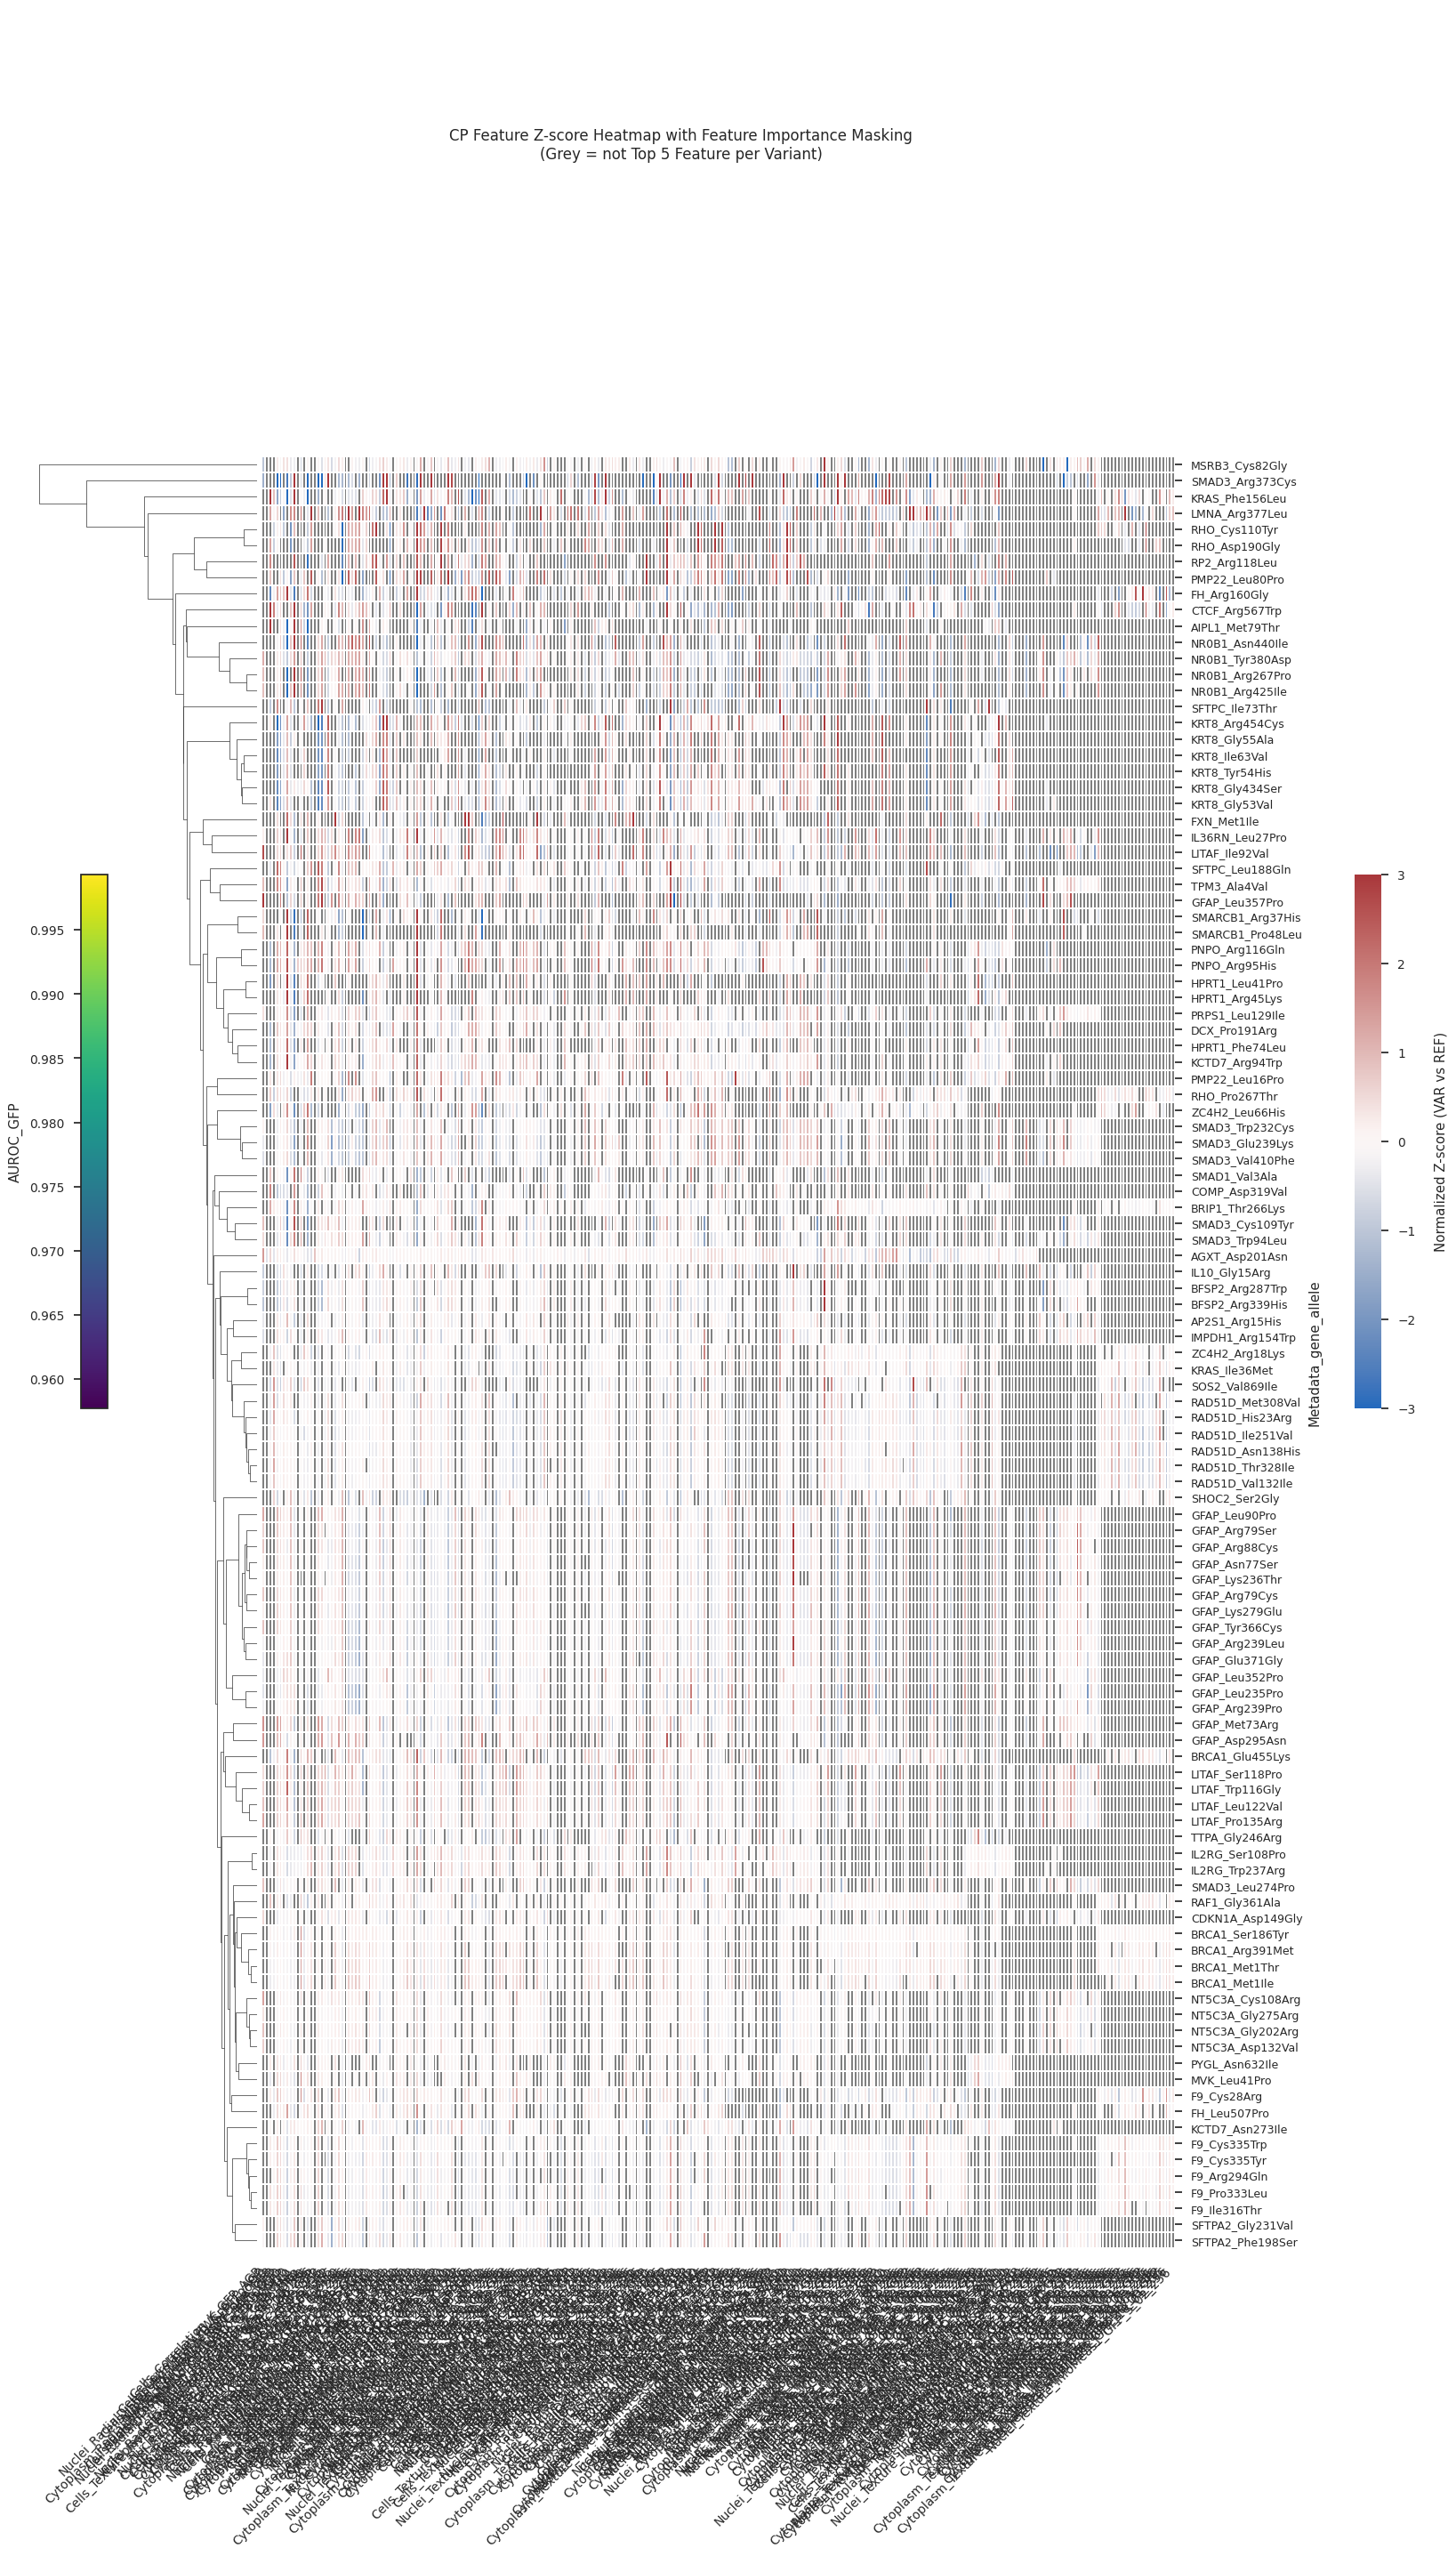

Applied mask with 12935/29637 values masked (43.6%)
Using 267 common features out of 267 significant features


In [159]:
from matplotlib.colors import Normalize

plt.clf()
hits_variants_scores = imaging_summary_clinvar.drop_nulls("AUROC_Mean_GFP_Adj").filter(
    pl.col("AUROC_Mean_GFP_Adj")>=0.9577
)["AUROC_Mean_GFP_Adj"].to_list()

hits_variants = allele_hits

# Create aligned datasets with matching shapes
heatmap_features = [c for c in sig_diff_feat if c in norm_vars_feat_df.columns]
importance_features = feat_df.select("cp_feature").to_pandas()["cp_feature"].tolist()
common_features = [f for f in heatmap_features if f in importance_features]

norm_vars_feat_df = norm_vars_feat_df.with_columns(
    [pl.col(feat).fill_null(0).alias(feat) for feat in sig_diff_feat]
)

# Create the heatmap data and mask with same dimensions
heatmap_data = norm_vars_feat_df.to_pandas().set_index("Metadata_gene_allele").loc[hits_variants, common_features]
importance_data = feat_df.fill_null(0).to_pandas().set_index("cp_feature").loc[common_features, hits_variants].T

# Create boolean mask where True values will be masked (shown as light grey)
mask = (importance_data == 0) | (importance_data < 0.001)

# Create a pandas Series with proper index
row_colors_series = pd.Series(hits_variants_scores, index=hits_variants, name='AUROC_GFP')

# Map to colors
norm = Normalize(vmin=row_colors_series.min(), vmax=row_colors_series.max())
# cmap = plt.cm.viridis
# row_colors = cmap(norm(row_colors_series.values))

# Create clustermap with mask and specify light grey for masked areas
g = sns.clustermap(
    data=heatmap_data,
    mask=mask,  # Apply the mask here
    cmap="vlag", 
    center=0,
    vmin=-3, vmax=3,
    # row_colors=row_colors,
    # row_cluster=False,
    col_cluster=False,
    cbar_pos=(1.005, 0.47, 0.02, 0.2),
    yticklabels=1, 
    xticklabels=1,
    figsize=(15, 30),
    linewidth=.1,
    # annot=True
    # Set the background color for the heatmap axes to light grey
    # This will show through for masked areas
)

# Set the background color of the heatmap to light grey
g.ax_heatmap.set_facecolor('grey')

g.fig.suptitle(f"CP Feature Z-score Heatmap with Feature Importance Masking\n(Grey = not Top {TOP_FEAT_NUM} Feature per Variant)", 
               fontsize=12, y=.95)
g.ax_heatmap.set_yticklabels(g.ax_heatmap.get_ymajorticklabels(), fontsize=9)
g.ax_heatmap.set_xticklabels(g.ax_heatmap.get_xmajorticklabels(), fontsize=10, rotation=45, ha='right')

# Add label to main heatmap colorbar
g.cax.set_ylabel('Normalized Z-score (VAR vs REF)', rotation=90, labelpad=15)

# Add colorbar for row colors on center left
row_cbar_ax = g.fig.add_axes([.05, 0.47, 0.02, 0.2])
cmap = plt.cm.viridis

row_cbar = plt.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), cax=row_cbar_ax)
row_cbar.set_label('AUROC_GFP', rotation=90, labelpad=5)
row_cbar.ax.yaxis.set_label_position('left')
row_cbar.ax.yaxis.tick_left()

plt.show()
print(f"Applied mask with {mask.sum().sum()}/{mask.size} values masked ({mask.sum().sum()/mask.size*100:.1f}%)")
print(f"Using {len(common_features)} common features out of {len(sig_diff_feat)} significant features")